# Trotter error under device noise

**Shengjie Xu · October 2026** · code and data: [github.com/jayhsu0627/qtrotter](https://github.com/jayhsu0627/qtrotter)

On a noisy quantum computer the number of Trotter steps r is a trade-off, not a precision dial: more steps shrink the
Trotter error but add gates, and gate noise grows with every one of them. So there is an optimal step count r\*. Two
analytic papers predict it from a single uniform gate error rate,
[Knee & Munro (2015)](https://arxiv.org/abs/1502.04536) and [Avtandilyan & Pogosov (2024)](https://arxiv.org/abs/2405.01131).
This notebook reproduces the ingredients and tests those predictions on 1D spin chains of 4 to 12 qubits under the
noise model of IBM's Torino processor.

**Findings**

1. **Error bounds (question 1).** On TFIM and XXZ chains the commutator bound of
   [Childs et al. (2021)](https://arxiv.org/abs/1912.08854) overestimates the worst-case Trotter error by about 6–7× at
   first order and 4× at second order, independent of chain length. The norm bound overestimates it by 10²–10³× at
   orders 1 and 2 and 10⁵–10⁸× at order 4, growing with n. Both match Childs et al.
2. **Predicted optimum (question 2).** Under the Torino noise model, the measured r\* ranges from 1 to 16, growing with
   evolution time. Knee & Munro's formula overshoots it by a median 2.4× and Avtandilyan & Pogosov's by 3.7×. To make
   Knee & Munro's exact, the per-step error would have to be about 11–12× the calibrated one.
3. **Why they overshoot.** The noise side of both models is fine; the Trotter side is a worst-case quantity. Replacing
   it with the actual noiseless Trotter error of the initial state (a cheap classical simulation) and keeping the
   calibrated gate errors predicts r\* within one grid step in all 45 configurations, fourth order included.
4. **Which order.** Grouping the Hamiltonian's commuting terms makes the second-order formula cost exactly as many
   two-qubit gates as the first, so it wins at every size and time tested. Fourth order (5× the gates) loses everywhere
   at today's error rates, in line with Avtandilyan & Pogosov.
5. **Pitfalls worth knowing.** Passed to Qiskit as one operator, the TFIM's second-order formula is *identical* to
   first order on Z-type observables from |0…0⟩, yet costs twice the gates. Single-observable errors are poor guides to
   r\*, because Trotter and noise errors can cancel.

Question 3, a check on a real IBM device, is pending (section 4).

## 0. Setup

Every number and figure below comes from the CSVs in `results/`, which `scripts/run_noiseless.py` and
`scripts/run_noisy.py` regenerate from `config.yaml`. The small demonstrations in section 1 run live.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))

from qtrotter import Model, Propagator, plots, predict, state_metrics, tfim
from qtrotter.circuits import choose_layout, device_circuit, trotter_circuit, two_qubit_count

cfg = yaml.safe_load(open(ROOT / "config.yaml"))
noiseless = pd.read_csv(ROOT / "results/noiseless.csv")
noisy = pd.read_csv(ROOT / "results/noisy.csv")
FIG = ROOT / "figures"
pd.set_option("display.precision", 3)
print(f"{len(noiseless)} noiseless rows, {len(noisy)} noisy rows")

720 noiseless rows, 540 noisy rows


## 1. Models, formulas and two implementation details

Two open chains:

$$H_\mathrm{TFIM} = -J\sum_{i=1}^{n-1} Z_iZ_{i+1} - h\sum_{i=1}^{n} X_i, \qquad
H_\mathrm{XXZ} = \sum_{i=1}^{n-1}\left(X_iX_{i+1} + Y_iY_{i+1} + \Delta Z_iZ_{i+1}\right),$$

with $J = h = 1$ and $\Delta = 0.5$. The TFIM starts in $|0\cdots0\rangle$; the XXZ chain starts in the Néel state
$|0101\cdots\rangle$, because $|0\cdots0\rangle$ is one of its eigenstates.

Each Hamiltonian is split into groups of mutually commuting terms, $H = A + B$: for the TFIM $A = $ the X field and
$B = $ the ZZ bonds; for XXZ, the even and odd bonds. The formulas are Lie–Trotter
$S_1(\delta) = e^{-iB\delta}e^{-iA\delta}$, Strang $S_2(\delta) = e^{-iA\delta/2}e^{-iB\delta}e^{-iA\delta/2}$, and
Suzuki's fourth order built from five $S_2$ stages. A NumPy implementation of the same formulas (exact group
exponentials) supplies noiseless errors; `tests/test_core.py` checks it against Qiskit's synthesized circuits.

**Detail 1: grouping halves the cost of higher orders.** Qiskit's `SuzukiTrotter` applied to the TFIM as a single
operator puts the ZZ terms outermost, so each second-order step carries two ZZ layers. Passing the groups as
`[X field, ZZ bonds]` puts the cheap single-qubit group outermost; half-steps of it merge between steps, leaving one
ZZ layer per step. Two-qubit gate count and depth after transpiling an 8-qubit chain, r = 16, onto Torino:

In [2]:
from qiskit_ibm_runtime.fake_provider import FakeTorino
from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

backend = FakeTorino()
model = tfim(8)
layout = choose_layout(model, backend)

def ungrouped_circuit(model, order, reps, t):
    qc = QuantumCircuit(model.n)
    synth = LieTrotter(reps=reps) if order == 1 else SuzukiTrotter(order=order, reps=reps)
    qc.append(PauliEvolutionGate(model.hamiltonian, time=t, synthesis=synth), range(model.n))
    return qc

rows = []
for order in (1, 2, 4):
    for label, qc in [("one operator", ungrouped_circuit(model, order, 16, 1.0)),
                      ("[X, ZZ] groups", trotter_circuit(model, order, 16, 1.0))]:
        tqc = device_circuit(qc, backend, layout, schedule=False)
        rows.append({"order": order, "Hamiltonian passed as": label,
                     "two-qubit gates": two_qubit_count(tqc), "depth": tqc.depth()})
pd.DataFrame(rows).pivot(index="order", columns="Hamiltonian passed as")

two-qubit gates                       depth             
Hamiltonian passed as  [X, ZZ] groups one operator [X, ZZ] groups one operator
order                                                                         
1                                 224          224            271          271
2                                 224          386            273         1435
4                                1120         1922           1264         7056

**Detail 2: the ungrouped second-order formula is secretly first order.** Writing the Strang step as $a\,b\,a$ with
$a = e^{-iB\delta/2}$, $r$ steps telescope: $S_2^r = a\,(b\,a^2)^r a^{-1} = a\,S_1^r a^{-1}$. With the diagonal ZZ group
outermost, $a$ is diagonal: it leaves $|0\cdots0\rangle$ unchanged up to a phase and commutes with every Z-type
observable. So first order and ZZ-outer second order give *identical* magnetizations and ZZ correlators, while the
second costs twice the gates. (This is the classical conjugacy of Lie and Strang splitting.) X-type observables and the
state itself do tell them apart:

In [3]:
base = tfim(8)
zz_outer = Model("tfim, ZZ outer", 8, base.groups[::-1], base.init_bits, base.params)
prop = Propagator(zz_outer)
obs = {k: v for k, v in base.observables().items() if k in ("mz", "zz_mid", "mx")}
exact = prop.exact_state(1.0)
rows = {}
for order in (1, 2):
    m = state_metrics(exact, prop.trotter_state(order, 8, 1.0), obs)
    rows[f"order {order}"] = {k: m[k] for k in ("mz_err", "zz_mid_err", "mx_err", "infidelity")}
pd.DataFrame(rows).T.map("{:.3e}".format)

,mz_err,zz_mid_err,mx_err,infidelity
order 1,4.704e-03,6.838e-03,4.977e-03,1.927e-02
order 2,4.704e-03,6.838e-03,5.928e-04,3.890e-04


All results below use the grouped form. Two more conventions: circuits are transpiled at optimization level 2 (level 1
leaves 6 CZ gates per XXZ bond instead of 3) with ALAP scheduling, so idle qubits decohere; and each chain keeps one
qubit layout, chosen once by the transpiler, for every r.

## 2. Question 1: how loose are Trotter error bounds?

For n ≤ 10 we compute the worst-case error $\lVert U(t) - S(t/r)^r\rVert$ (spectral norm) exactly and compare it with
two bounds:

* **Commutator bounds** (Childs et al. 2021): $\frac{t^2}{2r}\lVert[A,B]\rVert$ at first order and
  $\frac{t^3}{r^2}\left(\frac{1}{12}\lVert[B,[B,A]]\rVert + \frac{1}{24}\lVert[A,[A,B]]\rVert\right)$ at second.
* **Norm bound** (Taylor remainder): with $\Gamma = \sum_s |a_s|\,\lVert H_{j_s}\rVert$ summed over the formula's
  stages, $r \cdot 2(\Gamma t/r)^{p+1}/(p+1)!\;e^{\Gamma t/r}$. At first order this is the textbook $r = O(t^2/\epsilon)$.

`tests/test_core.py` checks that both bounds hold on every case swept.

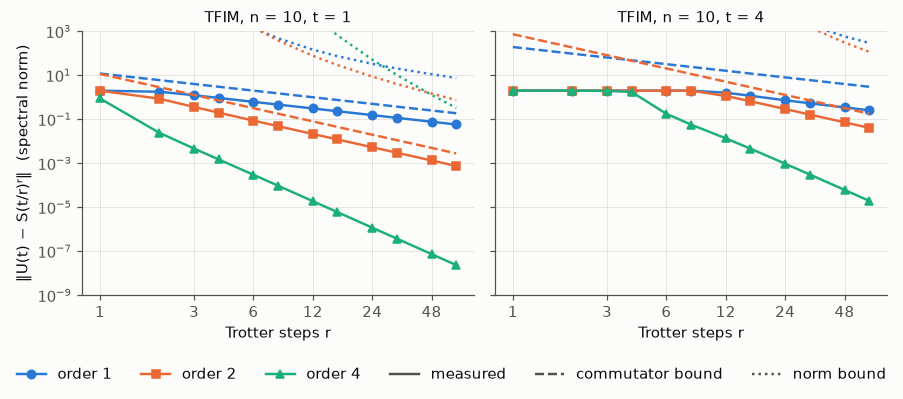

In [4]:
plots.bounds_vs_measured(noiseless, "tfim", 10, [1.0, 4.0], save=FIG / "fig1_bounds.png");

The measured errors fall as $r^{-1}$, $r^{-2}$ and $r^{-4}$ at t = 1. At t = 4 the steps are too coarse at small r:
the error saturates at its maximum of 2 until the formula enters its asymptotic regime. The ratio of each bound to the
measured error, median over r ≥ 16:

commutator      norm
model order                     
tfim  1           6.48       215
      2           4.03       816
      4            nan  1.17e+07
xxz   1           7.19       281
      2           3.84       808
      4            nan   1.3e+07

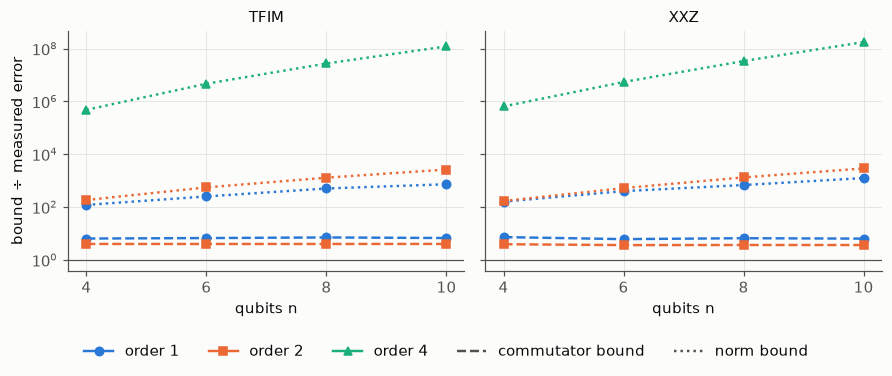

In [5]:
plots.bound_looseness(noiseless, save=FIG / "fig1b_looseness.png");
d = noiseless[(noiseless.r >= 16) & noiseless.spectral_err.notna()]
looseness = (d.assign(commutator=d.commutator_bound / d.spectral_err, norm=d.norm_bound / d.spectral_err)
               .groupby(["model", "order"])[["commutator", "norm"]].median())
looseness.map("{:.3g}".format)

The commutator bound stays within a constant factor of the truth (about 6–7× at first order, 4× at second) at every
chain length, because both it and the true error grow linearly with n. The norm bound grows like $n^{p+1}$ while the
true error grows like $n$, so its overestimate climbs with chain length, to 10³ at order 2 and 10⁸ at order 4 for
10 qubits. These reproduce Childs et al.'s conclusions on a different pair of models.

Worst-case bounds are what the analytic r\* formulas are built from, which matters in the next section.

## 3. Question 2: the optimal step count under device noise

Each TFIM circuit is transpiled onto `FakeTorino` and simulated as a density matrix with Qiskit Aer, using the
backend's calibrated noise: depolarizing and thermal-relaxation errors on every gate, separate one- and two-qubit rates,
and relaxation on idle qubits. Readout error is left out (on hardware it would be mitigated separately). The main
metric is the trace distance between the noisy output and the exact state $e^{-iHt}|\psi_0\rangle$.

The noise per Trotter step, from the calibration: the slope of the summed gate error of the transpiled circuit
against r. (Median CZ error on this snapshot is 4.2 × 10⁻³; single-qubit gates are about 15× better.)

In [6]:
summary = predict.summarize(noisy, noiseless)
(summary[summary.t == 1.0].pivot(index="n", columns="order", values=["twoq_per_step", "p_step"])
   .map("{:.3g}".format))

twoq_per_step           p_step               
order             1   2    4       1       2      4
n                                                  
4                 6   6   30  0.0238  0.0238  0.119
6                10  10   50  0.0387  0.0387  0.193
8                14  14   70  0.0859  0.0858   0.43
10               18  18   90  0.0751  0.0751  0.373
12               22  22  110   0.123   0.123  0.614

Orders 1 and 2 cost the same per step (the grouping at work); order 4 costs 5×. The per-step error is not monotonic in
n: the 8-qubit chain landed on noisier qubits than the 10-qubit one.

The trade-off at 8 qubits, for three evolution times. Solid lines include device noise; dashed lines are the noiseless
Trotter error of the same circuits; rings mark the measured optimum.

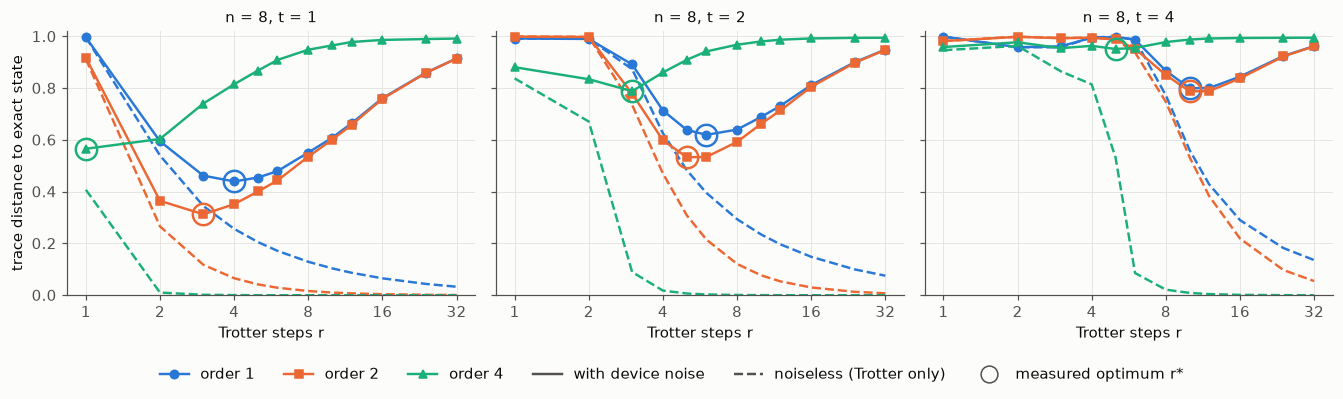

In [7]:
plots.noisy_tradeoff(noisy, 8, [1.0, 2.0, 4.0], save=FIG / "fig2_noisy_tradeoff.png");

The optimum moves to larger r as t grows, as both theories predict ($r^* \propto t$ at fixed hardware). The errors at
the optimum are large: at t = 4 even the best circuit sits at trace distance 0.8 from the target. At 10–12 qubits and
t = 4 the noisy state is close to maximally mixed for every r, so whole-state metrics saturate there.

Measured r\* for every chain length, time and order:

In [8]:
summary.pivot(index="n", columns=["t", "order"], values="r_measured").astype(int)

t     1.0       2.0       4.0       
order   1  2  4   1  2  4   1   2  4
n                                   
4       6  4  2   8  6  3  16  12  5
6       5  3  2   8  6  3  12  12  6
8       4  3  1   6  5  3  10  10  5
10      4  3  2   6  6  3  12  12  6
12      4  3  1   6  5  3  12  12  6

### Predicted against measured

Both papers minimize $a/r^q + b\,r$, giving $r^* = (q\,a/b)^{1/(q+1)}$. We feed each its own Trotter constant $a$
and take $b$ from the calibration above:

* **Knee & Munro**, first order with depolarizing noise $p$ per step, in diamond norm:
  $D(r) \approx (1-p)\,\mathscr{A}\,t^2/(2r) + 2pr$, where $\mathscr{A}$ is the diamond norm of
  $\rho \mapsto [\,[A,B],\rho\,]$, the spectral spread of $i[A,B]$. For second order we use their general form with our
  commutator bound as the Trotter constant.
* **Avtandilyan & Pogosov**, TFIM with explicit constants: $a = t^2 Jh(n-1)$ at first order and
  $a = 4t^3Jh(J+h)(n-1)$ at second. Their estimates are order-of-magnitude (written with "∼"); we use them as published.
* **Semi-empirical (this work):** keep the calibrated per-step error $p$, but replace the analytic Trotter term with the
  actual noiseless Trotter error $E_T(r)$ of the initial state, and treat the two as independent failures:
  minimize $1 - (1 - E_T(r))\,e^{-pr}$. No noisy simulation is needed.

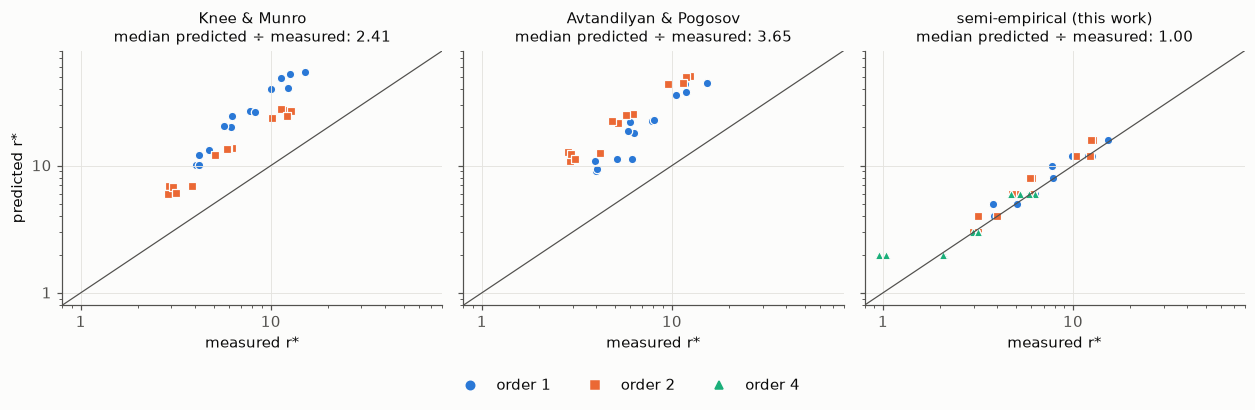

In [9]:
plots.predicted_vs_measured(summary, save=FIG / "fig3_predictions.png");

In [10]:
low = summary[summary.order <= 2]
ratio = lambda col: low[col] / low.r_measured
table = pd.DataFrame({
    "Knee & Munro": ratio("r_knee_munro").groupby(low.order).median(),
    "Avtandilyan & Pogosov": ratio("r_avtandilyan_pogosov").groupby(low.order).median(),
    "semi-empirical": ratio("r_semi_empirical").groupby(low.order).median(),
})
table.index.name = "order"
print("Median predicted r* / measured r*")
display(table.round(2))

# Per-step error that would make each analytic formula exact: b scales as (predicted/measured)^(q+1), q = order.
mult = pd.DataFrame({name: (ratio(col) ** (low.order + 1)).groupby(low.order).median()
                     for name, col in [("Knee & Munro", "r_knee_munro"),
                                       ("Avtandilyan & Pogosov", "r_avtandilyan_pogosov")]})
mult.index.name = "order"
print("Per-step error needed for an exact prediction, as a multiple of the calibrated one")
display(mult.round(1))

grid = np.sort(noisy.r.unique())
step_apart = lambda a, b: abs(np.searchsorted(grid, a) - np.searchsorted(grid, b)) <= 1
hit = summary.apply(lambda s: step_apart(s.r_semi_empirical, s.r_measured), axis=1)
print("Semi-empirical r* within one grid step of measured:", hit.groupby(summary.order).mean().map("{:.0%}".format).to_dict())

Median predicted r* / measured r*


,Knee & Munro,Avtandilyan & Pogosov,semi-empirical
order,,,
1,3.38,2.84,1.0
2,2.30,4.21,1.2


Per-step error needed for an exact prediction, as a multiple of the calibrated one


,Knee & Munro,Avtandilyan & Pogosov
order,,
1,11.4,8.1
2,12.1,74.7


Semi-empirical r* within one grid step of measured: {1: '100%', 2: '100%', 4: '100%'}


Both analytic formulas get the scaling right and the level wrong, always on the high side. The cause is the Trotter
term, not the noise term. Both use a worst-case quantity (an operator or diamond norm over all input states), which
section 2 showed already overestimates by 4–7× before the state-specific error of this one initial state shrinks the
real Trotter error further. Since $r^* \propto a^{1/(q+1)}$, an inflated Trotter constant inflates r\*, and the
semi-empirical predictor removes the overshoot by changing only that term.

Answering question 2 as posed: Knee & Munro's prediction becomes accurate if the effective error per step is set about
11–12× above the calibrated value. That number is not a property of the hardware, though; it absorbs the looseness of the
Trotter term, so it would change with the initial state and the evolution time.

### Which order to use

Lowest trace distance reached by each order, at its own optimum:

In [11]:
best = summary.pivot(index=["n", "t"], columns="order", values="err_at_optimum")
best["best order"] = best.idxmin(axis=1)
best.round(3)

order       1      2      4  best order
n  t                                   
4  1.0  0.199  0.119  0.232           2
   2.0  0.295  0.223  0.359           2
   4.0  0.439  0.401  0.558           2
6  1.0  0.281  0.178  0.347           2
   2.0  0.410  0.324  0.511           2
   4.0  0.571  0.557  0.768           2
8  1.0  0.440  0.313  0.566           2
   2.0  0.620  0.533  0.789           2
   4.0  0.800  0.788  0.952           2
10 1.0  0.433  0.292  0.564           2
   2.0  0.602  0.506  0.754           2
   4.0  0.786  0.766  0.943           2
12 1.0  0.558  0.420  0.697           2
   2.0  0.732  0.661  0.891           2
   4.0  0.901  0.890  0.988           2

Second order wins at every size and time. Avtandilyan & Pogosov find first order optimal at error rates like these,
but their cost model charges the second-order formula twice the gates of the first; with grouping it costs the same, so
it is a free improvement. Fourth order needs 5× the gates and loses everywhere, consistent with their conclusion that
higher orders pay off only after roughly a tenfold drop in gate error.

### A caution on single observables

Errors in one observable are a poor way to locate r\*. Trotter error has a sign, noise mostly shrinks expectation values
toward zero, and the two can cancel. The minima of single-observable errors scatter where the trace distance does not:

In [12]:
obs_cols = {"trace_dist": "trace distance", "mz_err": "<M_z> error", "mx_err": "<M_x> error", "zz_mid_err": "<ZZ> error"}
rstar = {label: noisy.loc[noisy.groupby(["n", "t", "order"])[col].idxmin()].set_index(["n", "t", "order"]).r
         for col, label in obs_cols.items()}
pd.DataFrame(rstar).astype(int).xs(2, level="order").T

n               4           6           8           10          12        
t              1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0 1.0 2.0 4.0
trace distance   4   6  12   3   6  12   3   5  10   3   6  12   3   5  12
<M_z> error      6  32  12   5  12   8   5  12   5   5  16   4   5  10   4
<M_x> error      3   8   8   2   4  16   2   4   8   2   5   8   2   5   8
<ZZ> error       1   5   6   3   1  12   2   2   2   3   5   8   2   4   3

For second order, the trace-distance optimum grows steadily with t (3–4, then 5–6, then 10–12). The magnetization's
optimum instead jumps to 10–32 at t = 2 and falls back to 4–5 at t = 4, and the mid-chain ZZ correlator's wanders between
1 and 12 with no pattern. On hardware, where only observables are available, several
of them (or an observable with a known noise response) are needed to place r\* reliably.

## 4. Question 3: hardware check (pending)

Plan: one TFIM chain at three values of r around the simulated optimum, run with the Qiskit Runtime Estimator on an IBM
device under the free Open Plan, measuring X- and Z-type observables with readout mitigation, compared with the
noise-model prediction for the same circuits. This needs an IBM Quantum account and has not been run yet.

## 5. Limitations

* One noise snapshot (Torino), simulated with Aer's model: gate depolarizing plus thermal relaxation, no crosstalk,
  leakage or drift. IBM notes such models are usually milder than a real device, so hardware r\* is probably smaller.
* r is sampled on a grid, so measured r\* has grid-step resolution (about ±25% at the values found).
* Avtandilyan & Pogosov's constants are order-of-magnitude estimates, and their higher orders use a different
  (complex-coefficient) family from the standard Suzuki formulas used here; only their orders 1 and 2 are compared.
* Whole-state metrics saturate at 10–12 qubits under this noise; the predictions there rest on the trace distance
  near its ceiling.

## References

1. G. C. Knee, W. J. Munro, *Optimal Trotterization in universal quantum simulators under faulty control*,
   Phys. Rev. A 91, 052327 (2015). [arXiv:1502.04536](https://arxiv.org/abs/1502.04536)
2. A. A. Avtandilyan, W. V. Pogosov, *Optimal-order Trotter–Suzuki decomposition for quantum simulation on noisy
   quantum computers*. [arXiv:2405.01131](https://arxiv.org/abs/2405.01131)
3. A. M. Childs, Y. Su, M. C. Tran, N. Wiebe, S. Zhu, *Theory of Trotter error with commutator scaling*,
   Phys. Rev. X 11, 011020 (2021). [arXiv:1912.08854](https://arxiv.org/abs/1912.08854)
4. Y. Kim et al., *Evidence for the utility of quantum computing before fault tolerance*, Nature 618, 500 (2023).